# Лабораторная работа 4
## Расчёт зависимости коэффициента липофильности от структуры молекул с помощью двухслойного перцептрона

### 1. Данные

Использую файл `lipo.csv`: 82 вещества, 24 дескриптора и цель `logP`.
Признаки и цель берутся в исходных единицах, без масштабирования и повторного логарифмирования.

In [1]:
from pathlib import Path
import sys
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.neural_network import MLPRegressor
from sklearn.exceptions import ConvergenceWarning

ROOT = Path.cwd().resolve()
if (ROOT / 'perceptron.py').is_file():
    ROOT = ROOT.parent
LAB_DIR = ROOT / 'Lab4'
sys.path.insert(0, str(ROOT / 'Lab3'))
sys.path.insert(0, str(LAB_DIR))
from regression import FEATURES, load_data, fit_ols, metrics
from perceptron import train, predict, loss_gradient, gradient_norm, save_model, predict_saved

FIG_DIR = LAB_DIR / 'figures'
RESULT_DIR = LAB_DIR / 'results'
MODEL_DIR = LAB_DIR / 'models'
for directory in (FIG_DIR, RESULT_DIR, MODEL_DIR):
    directory.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_rows', 100)
pd.set_option('display.max_columns', 12)
pd.set_option('display.float_format', lambda value: f'{value:.6g}')

df = load_data(LAB_DIR / 'lipo.csv')
X = df[FEATURES].to_numpy(float)
y = df.logP.to_numpy(float)
names = df.iloc[:, 0].to_numpy()
display(df.head())
print(f'Число веществ: {len(y)}; число признаков: {X.shape[1]}')
print('Пропуски:', int(df.isna().sum().sum()))

,Вещество,logP,RNH2,R2NH,R3N,ROPO3,...,AROMATIC,HBA1,HBA2,HBD,PSA,MR
0,Acetamide,-1.26,0,0,0,0,...,0,2,2,1,43.09,14.6354
1,Acetanilide,1.16,0,1,0,0,...,1,2,2,1,29.1,40.7547
2,Acetazolamide,-0.26,0,1,0,0,...,1,7,8,2,151.66,45.2161
3,Acetic acid,-0.17,0,0,0,0,...,0,2,2,1,37.3,13.4998
4,Acetohexamide,2.44,0,1,0,0,...,1,6,6,2,100.72,82.6509


Число веществ: 82; число признаков: 24
Пропуски: 0


### 2. Архитектуры и производные

Рассматриваю $h\in\{2,4,8,16,32\}$ скрытых нейронов:

$$U=XW_1+b_1,\qquad H=\operatorname{ReLU}(U),\qquad
\widehat y=Hw_2+b_2.$$

Двухслойный перцептрон состоит из одного скрытого слоя ReLU и одного линейного выходного слоя.
$W_1$ имеет размер $24\times h$, $b_1$ и $w_2$ — по $h$ компонент, $b_2$ — скаляр.
Всего получается $26h+1$ параметров: 53, 105, 209, 417 и 833.

Для суммы квадратов ошибок:

$$J=\sum_i(\widehat y_i-y_i)^2,\qquad d=2(\widehat y-y),$$
$$\nabla_{w_2}J=H^Td,\qquad \nabla_{b_2}J=\sum_i d_i,$$
$$D=(dw_2^T)\odot\mathbf1_{U\ge0},\qquad
\nabla_{W_1}J=X^TD,\qquad\nabla_{b_1}J=\sum_iD_i.$$

В нуле ReLU не имеет классической производной. Для вычисления градиента
принята маска $\mathbf1_{U\ge0}$, то есть условное значение 1 в нуле.
Вычисляется полный градиент суммы квадратов $J$, поэтому обновление записано со знаком минус:
$\theta_{k+1}=\theta_k-\varepsilon_k\nabla J(\theta_k)$.

### 3. Фиксированные параметры и обучение

Фиксирую $\varepsilon=10^{-6}$, $\delta=0.001$ и лимит 30 000 обновлений.
Малый шаг выбран для исходных признаков: PSA и MR имеют значения порядка сотен,
а функция потерь представляет сумму, а не среднее квадратов.

Начальные веса равномерно выбираются из $[-0.1,0.1]$, смещения равны нулю.
Для воспроизводимости фиксирован `seed=2026`.
Остановка выполняется при $\|\nabla J\|_\infty<\delta$.
Достижение лимита не считается сходимостью.

Для эксперимента с уменьшением скорости на каждой итерации использую
$\varepsilon_k=\varepsilon/(1+k/1000)$.
В паре запусков одной архитектуры начальные параметры одинаковы.

In [2]:
WIDTHS = (2, 4, 8, 16, 32)
SCHEDULES = ('constant', 'decay')
LR, DELTA, MAX_ITER, SEED = 1e-6, 1e-3, 30000, 2026
settings = {'seed': SEED, 'widths': WIDTHS, 'learning_rate': LR, 'tolerance': DELTA,
            'max_iter': MAX_ITER, 'loss': 'sum of squared errors, raw inputs and target',
            'decay': 'learning_rate / (1 + step / 1000)',
            'stopping': 'infinity norm of gradient < tolerance', 'Heaviside_at_zero': 1}
(RESULT_DIR / 'settings.json').write_text(json.dumps(settings, indent=2), encoding='utf-8')
models, rows = {}, []
for h in WIDTHS:
    for schedule in SCHEDULES:
        result = train(X, y, h, learning_rate=LR, tolerance=DELTA,
                       max_iter=MAX_ITER, schedule=schedule, seed=SEED)
        models[h, schedule] = result
        pred = predict(X, result.params)
        rows.append({'hidden': h, 'schedule': schedule, 'parameters': 26 * h + 1,
                     'iterations': result.iterations, 'converged': result.converged,
                     'gradient_inf': result.grad_norm, 'SSE': result.loss, **metrics(y, pred)})
        save_model(MODEL_DIR / f'mlp_h{h}_{schedule}.npz', result)
        pd.DataFrame(result.history, columns=['step', 'SSE', 'gradient_inf', 'learning_rate']).to_csv(
            RESULT_DIR / f'history_h{h}_{schedule}.csv', index=False)
train_table = pd.DataFrame(rows)
display(train_table)
train_table.to_csv(RESULT_DIR / 'training.csv', index=False)

,hidden,schedule,parameters,iterations,converged,gradient_inf,SSE,MSE,RMSE,R2
0,2,constant,53,30000,False,13.5154,53.5825,0.653445,0.808359,0.74229
1,2,decay,53,30000,False,15.9167,67.3192,0.820966,0.906072,0.676222
2,4,constant,105,30000,False,7.92659,48.8749,0.596035,0.772033,0.764932
3,4,decay,105,30000,False,12.795,64.483,0.786378,0.88678,0.689863
4,8,constant,209,30000,False,8.6363,48.8605,0.59586,0.77192,0.765001
5,8,decay,209,30000,False,21.2805,66.504,0.811024,0.900569,0.680143
6,16,constant,417,30000,False,22.2261,50.6725,0.617957,0.786103,0.756286
7,16,decay,417,30000,False,33.342,63.4109,0.773304,0.879377,0.69502
8,32,constant,833,30000,False,74.1619,41.8464,0.510322,0.714368,0.798736
9,32,decay,833,30000,False,66.672,61.4192,0.749015,0.865456,0.704599


### 4. Число итераций, сходимость и уменьшение шага

В таблице `iterations` означает число выполненных обновлений,
`gradient_inf` — конечную норму градиента, `converged` — выполнение критерия $\delta$.
Снижение суммы квадратов ошибок само по себе не означает сходимость.
Кривые ниже показывают ошибку и выполнение критерия для всех архитектур.

Во всех десяти запусках выполнено 30 000 обновлений, но точность δ не достигнута. Убывающий шаг дал более высокую обучающую RMSE для каждой ширины. При одинаковом лимите уменьшение шага замедлило снижение ошибки.

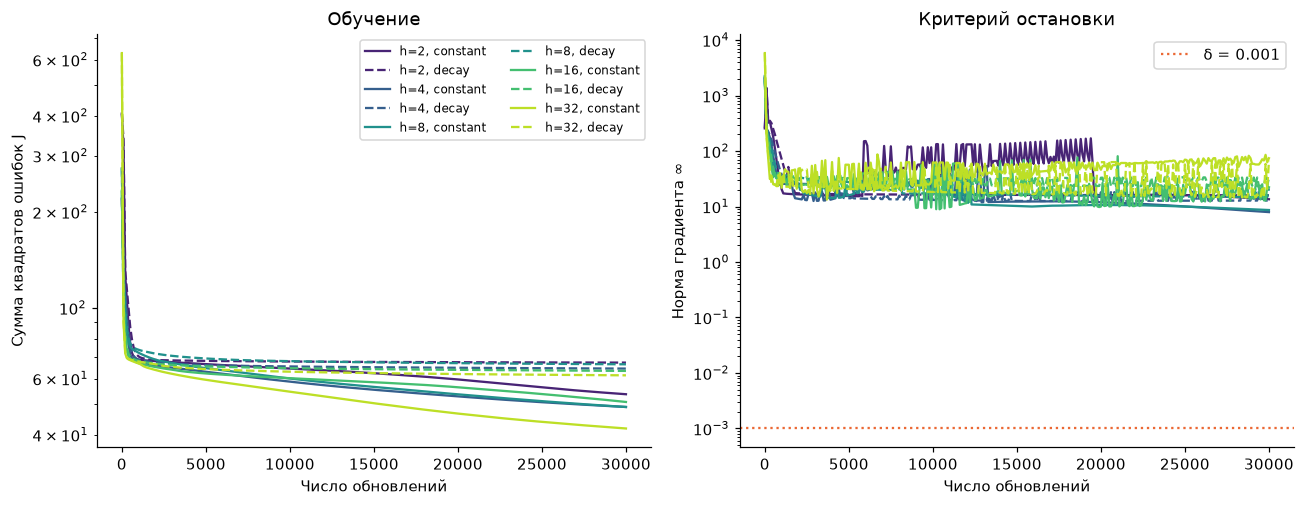

Число собственных запусков с выполненным критерием: 0


schedule,constant,decay
hidden,,
2,0.808359,0.906072
4,0.772033,0.88678
8,0.77192,0.900569
16,0.786103,0.879377
32,0.714368,0.865456


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.7))
colors = plt.cm.viridis(np.linspace(.1, .9, len(WIDTHS)))
for h, color in zip(WIDTHS, colors):
    for schedule, style in [('constant', '-'), ('decay', '--')]:
        history = models[h, schedule].history
        axes[0].semilogy(history[:, 0], history[:, 1], style, color=color, label=f'h={h}, {schedule}')
        axes[1].semilogy(history[:, 0], history[:, 2], style, color=color)
axes[1].axhline(DELTA, color='#eb6834', linestyle=':', label='δ = 0.001')
axes[0].set(xlabel='Число обновлений', ylabel='Сумма квадратов ошибок J', title='Обучение')
axes[1].set(xlabel='Число обновлений', ylabel='Норма градиента ∞', title='Критерий остановки')
axes[0].legend(fontsize=8, ncol=2)
axes[1].legend()
fig.tight_layout()
fig.savefig(FIG_DIR / 'learning_curves.png', bbox_inches='tight')
plt.show()
print('Число собственных запусков с выполненным критерием:', int(train_table.converged.sum()))
comparison_steps = train_table.pivot(index='hidden', columns='schedule', values='RMSE')
display(comparison_steps)

### 5. Сравнение с scikit-learn

Для каждой ширины строю `MLPRegressor` с ReLU, SGD, полным набором наблюдений
в одном шаге, без регуляризации и momentum. Используются исходные признаки и цель.

В собственной реализации $J=\sum_i e_i^2$, а в библиотеке квадратичная потеря
нормирована как $J/(2n)$. Чтобы учесть этот постоянный множитель в обновлениях,
задаю библиотечный шаг $2n\varepsilon=0.000164$.
Начальные веса библиотека задаёт самостоятельно, поэтому одинаковые конечные веса не ожидаются.

Значение `n_iter_no_change` превышает лимит обновлений, поэтому встроенная
остановка по изменению потерь в пределах этого запуска не срабатывает.
После обучения отдельно вычисляю норму градиента исходной суммы квадратов и проверяю $\delta$.
Это проверка конечного состояния, а не определение первого момента достижения точности.

In [4]:
library_rows = []
for h in WIDTHS:
    net = MLPRegressor(hidden_layer_sizes=(h,), activation='relu', solver='sgd',
                       alpha=0, batch_size=len(y), learning_rate='constant',
                       learning_rate_init=2 * len(y) * LR, max_iter=MAX_ITER,
                       shuffle=False, random_state=SEED, tol=0,
                       n_iter_no_change=MAX_ITER + 1, momentum=0,
                       nesterovs_momentum=False, early_stopping=False)
    with warnings.catch_warnings(record=True) as captured:
        warnings.simplefilter('always', ConvergenceWarning)
        net.fit(X, y)
    params = [net.coefs_[0], net.intercepts_[0], net.coefs_[1][:, 0], net.intercepts_[1]]
    loss, gradients = loss_gradient(X, y, params)
    norm = gradient_norm(gradients)
    library_rows.append({'hidden': h, 'iterations': net.n_iter_, 'SSE': loss,
                         'gradient_inf': norm, 'our_criterion': norm < DELTA,
                         'limit_warning': any(issubclass(w.category, ConvergenceWarning) for w in captured),
                         **metrics(y, net.predict(X))})
library_table = pd.DataFrame(library_rows)
display(library_table)
library_table.to_csv(RESULT_DIR / 'sklearn_comparison.csv', index=False)
display(train_table.query("schedule == 'constant'")[['hidden', 'RMSE', 'R2']].merge(
    library_table[['hidden', 'RMSE', 'R2']], on='hidden', suffixes=('_manual', '_sklearn')))

,hidden,iterations,SSE,gradient_inf,our_criterion,limit_warning,MSE,RMSE,R2
0,2,30000,47.9142,154.466,False,True,0.58432,0.764408,0.769552
1,4,30000,207.934,2.3228,False,True,2.53579,1.59242,-7.91145e-05
2,8,30000,59.947,42.2129,False,True,0.731061,0.855021,0.71168
3,16,30000,52.2528,8.08269,False,True,0.637229,0.798266,0.748686
4,32,30000,56.1508,28.2083,False,True,0.684766,0.827506,0.729938


,hidden,RMSE_manual,R2_manual,RMSE_sklearn,R2_sklearn
0,2,0.808359,0.74229,0.764408,0.769552
1,4,0.772033,0.764932,1.59242,-7.91145e-05
2,8,0.77192,0.765001,0.855021,0.71168
3,16,0.786103,0.756286,0.798266,0.748686
4,32,0.714368,0.798736,0.827506,0.729938


### 6. Адекватность модели и сравнение с линейной регрессией

Для сравнения вычисляю МНК заново. Используется функция нормальных уравнений из `Lab3/regression.py`.

Показатели ниже характеризуют описание одних и тех же 82 веществ.
По обучающей ошибке нельзя установить качество для новых молекул.
При $h\ge4$ число параметров уже превышает число наблюдений, а универсальная
аппроксимация не гарантирует, что градиентный спуск найдёт подходящие веса.

,model,hidden,schedule,SSE,MSE,RMSE,R2
0,h2_constant,2,constant,53.5825,0.653445,0.808359,0.74229
1,h2_decay,2,decay,67.3192,0.820966,0.906072,0.676222
2,h4_constant,4,constant,48.8749,0.596035,0.772033,0.764932
3,h4_decay,4,decay,64.483,0.786378,0.88678,0.689863
4,h8_constant,8,constant,48.8605,0.59586,0.77192,0.765001
5,h8_decay,8,decay,66.504,0.811024,0.900569,0.680143
6,h16_constant,16,constant,50.6725,0.617957,0.786103,0.756286
7,h16_decay,16,decay,63.4109,0.773304,0.879377,0.69502
8,h32_constant,32,constant,41.8464,0.510322,0.714368,0.798736
9,h32_decay,32,decay,61.4192,0.749015,0.865456,0.704599


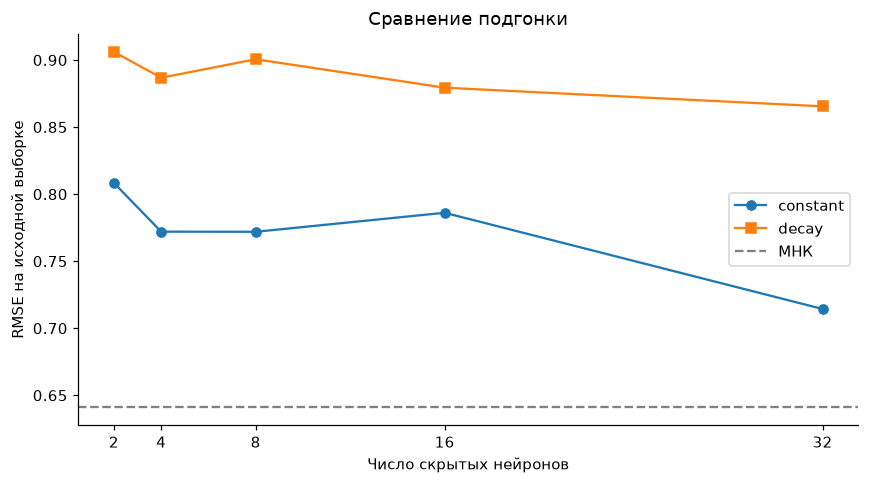

In [5]:
ols = fit_ols(X, y)
model_comparison = train_table[['hidden', 'schedule', 'SSE', 'MSE', 'RMSE', 'R2']].copy()
model_comparison.insert(0, 'model', [f'h{h}_{schedule}' for h, schedule in zip(train_table.hidden, train_table.schedule)])
model_comparison = pd.concat([model_comparison, pd.DataFrame([
    {'model': 'МНК', 'hidden': 0, 'schedule': '-', 'SSE': ols.sse, **metrics(y, ols.fitted)}
])], ignore_index=True)
display(model_comparison)
model_comparison.to_csv(RESULT_DIR / 'model_comparison.csv', index=False, encoding='utf-8-sig')
fig, ax = plt.subplots(figsize=(8, 4.5))
for schedule, marker in [('constant', 'o'), ('decay', 's')]:
    subset = train_table[train_table.schedule == schedule]
    ax.plot(subset.hidden, subset.RMSE, marker=marker, label=schedule)
ax.axhline(metrics(y, ols.fitted)['RMSE'], color='gray', linestyle='--', label='МНК')
ax.set(xlabel='Число скрытых нейронов', ylabel='RMSE на исходной выборке', title='Сравнение подгонки')
ax.set_xticks(WIDTHS)
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / 'model_comparison.png', bbox_inches='tight')
plt.show()

### 7. Вклад регрессоров

Для сети с 8 нейронами и постоянным шагом рассматриваю изменение прямого прогноза
при изменении одного входа. Остальные признаки фиксируются на средних значениях выборки:

$$\Delta_j=f(\overline x_1,\ldots,x_j^{max},\ldots,\overline x_{24})
-f(\overline x_1,\ldots,x_j^{min},\ldots,\overline x_{24}).$$

Для расчёта используется только формула перцептрона из задания.
Такое сравнение показывает поведение модели в выбранном диапазоне входа;
оно не устанавливает химический эффект и не обязано совпадать при других фиксированных входах.
Для линейной модели то же изменение равно $b_j(x_j^{max}-x_j^{min})$.

,feature,min,max,prediction_low,prediction_high,prediction_change,linear_change,abs_change
23,MR,12.8898,211.956,-0.571024,7.70839,8.27941,-7.08221,8.27941
22,PSA,0,198.03,4.45849,0.108461,-4.35003,-10.5509,4.35003
19,HBA1,0,18,2.45017,-0.859019,-3.30919,-7.77755,3.30919
16,C,2,40,0.7418,3.66494,2.92314,16.2554,2.92314
12,RF,0,3,1.52394,1.92789,0.403952,1.14918,0.403952
9,ROR,0,3,1.5764,1.31125,-0.265151,-0.822071,0.265151
0,RNH2,0,2,1.55681,1.38987,-0.166943,0.305109,0.166943
20,HBA2,0,14,1.58158,1.44815,-0.133432,14.3282,0.133432
18,AROMATIC,0,4,1.48628,1.6163,0.130021,0.881577,0.130021
6,RCOR,0,2,1.54064,1.41869,-0.12195,-1.07626,0.12195


Наибольшее изменение прогноза по модулю: MR, PSA, HBA1, C, RF
Наименьшее изменение прогноза по модулю: RCHO, RSO2R, ROPO3


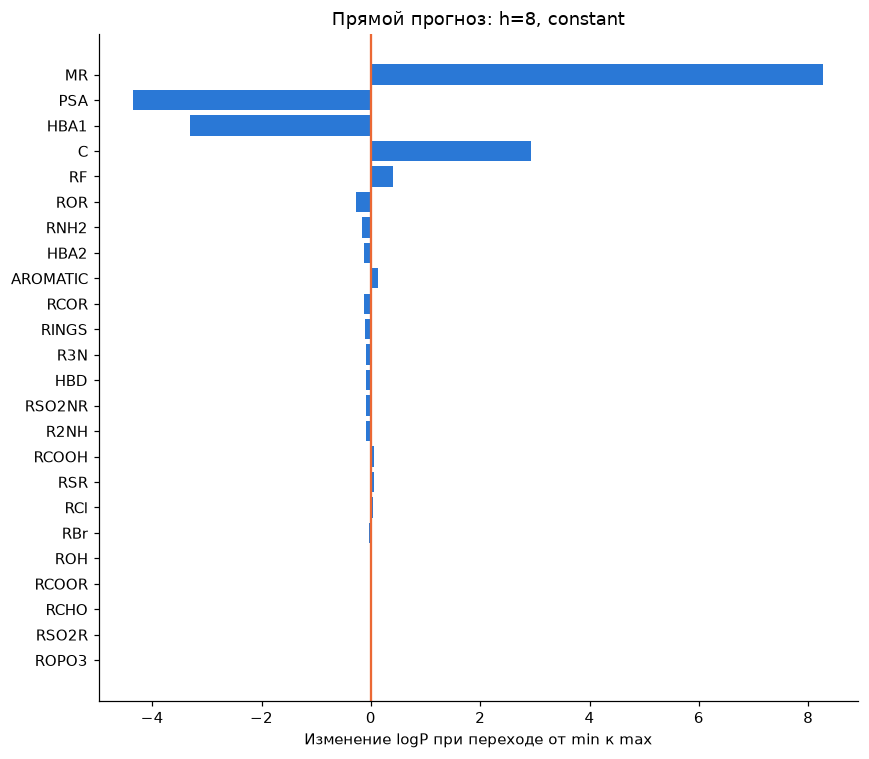

In [6]:
chosen = models[8, 'constant']
reference = X.mean(axis=0)
low = np.tile(reference, (len(FEATURES), 1))
high = low.copy()
for j in range(len(FEATURES)):
    low[j, j] = X[:, j].min()
    high[j, j] = X[:, j].max()
low_prediction = predict(low, chosen.params)
high_prediction = predict(high, chosen.params)
effects = pd.DataFrame({'feature': FEATURES, 'min': X.min(axis=0), 'max': X.max(axis=0),
                        'prediction_low': low_prediction, 'prediction_high': high_prediction,
                        'prediction_change': high_prediction - low_prediction,
                        'linear_change': ols.coef[1:] * (X.max(axis=0) - X.min(axis=0))})
effects['abs_change'] = abs(effects.prediction_change)
effects = effects.sort_values('abs_change', ascending=False)
display(effects)
effects.to_csv(RESULT_DIR / 'feature_effects.csv', index=False)
print('Наибольшее изменение прогноза по модулю:', ', '.join(effects.feature.head(5)))
print('Наименьшее изменение прогноза по модулю:', ', '.join(effects.feature.tail(3)))
fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(effects.feature, effects.prediction_change, color='#2a78d6')
ax.invert_yaxis()
ax.axvline(0, color='#eb6834')
ax.set(xlabel='Изменение logP при переходе от min к max', title='Прямой прогноз: h=8, constant')
fig.tight_layout()
fig.savefig(FIG_DIR / 'feature_effects.png', bbox_inches='tight')
plt.show()

Наибольшие по модулю изменения прямого прогноза получены для MR, PSA, HBA1, C и RF; наименьшие — для ROPO3, RSO2R и RCHO. Для C изменение положительно, для PSA — отрицательно.

Увеличение углеродного скелета обычно связывается с ростом сродства к органической фазе,
а увеличение полярной части — со сродством к воде. Поэтому для C ожидается положительное,
а для PSA — отрицательное направление изменения. Для проверки нужно сопоставить эти ожидания
с прямыми расчётами модели. Знаки относятся к выбранным фиксированным входам и диапазонам признаков.
Различие с МНК само по себе не устанавливает, какая модель точнее. Комбинация средних значений дескрипторов также не обязана соответствовать реальной молекуле.

### 8. Полученные веса

Все десять наборов весов сохранены в `models/`. Они относятся к исходным единицам входов.
Для примера ниже приведены все параметры сети с 8 нейронами и постоянным шагом.

In [7]:
w1, b1, w2, b2 = chosen.params
display(pd.DataFrame(w1, index=FEATURES, columns=[f'neuron_{j+1}' for j in range(8)]))
display(pd.DataFrame({'b1': b1, 'w2': w2}))
print('b2 =', b2[0])
saved = predict_saved(MODEL_DIR / 'mlp_h8_constant.npz', X)
np.testing.assert_allclose(saved, predict(X, chosen.params))
predictions = pd.DataFrame({'Вещество': names, 'logP': y, 'prediction': saved, 'residual': y - saved})
display(predictions.head(10))
predictions.to_csv(RESULT_DIR / 'predictions_h8.csv', index=False, encoding='utf-8-sig')
print('Прогнозы до и после загрузки весов совпадают.')

,neuron_1,neuron_2,neuron_3,neuron_4,neuron_5,neuron_6,neuron_7,neuron_8
RNH2,-0.0507171,0.0279826,-0.0415549,-0.0258999,-0.11482,0.116531,0.0964518,-0.0329649
R2NH,0.0393178,-0.0403394,0.0706984,0.08397,-0.0239313,0.0842161,0.014395,0.0835729
R3N,0.00341147,-0.0333833,-0.0799787,-0.0547334,-0.0804375,0.0440522,0.0485762,-0.065946
ROPO3,-0.0110643,-0.0269638,-0.059354,0.0189732,-0.00850017,-0.0431606,-0.0586061,0.0732206
ROH,0.0551534,0.0213419,-0.0197139,0.089364,0.039977,-0.0319031,0.07515,-0.0461479
RCHO,0.0388091,-0.036281,-0.0466374,0.0401682,-0.0519941,-0.00295361,0.0155666,-0.0630893
RCOR,0.0568334,0.00774961,-0.00270594,-0.0255711,-0.0837413,0.0457344,0.0055916,0.0603438
RCOOH,0.00378211,-0.0167459,-0.0694171,0.0588062,0.0770614,-0.0842566,-0.013498,-0.10821
RCOOR,0.0799513,0.0979472,-0.0856837,-0.0283538,0.0539135,-0.0428937,0.0128284,-0.0197556
ROR,0.0669408,0.0827705,0.046672,0.0241871,-0.137404,0.135311,-0.0797053,-0.0154511


,b1,w2
0,-0.00014867,-0.0510117
1,0.00329441,0.249603
2,0.00566427,0.134086
3,0,-0.000266228
4,0.00292843,0.410465
5,0.00356624,-0.298338
6,-0.00219887,-0.0390773
7,0.000900365,-0.157053


b2 = 0.06772206715276788


,Вещество,logP,prediction,residual
0,Acetamide,-1.26,-0.18015,-1.07985
1,Acetanilide,1.16,1.38258,-0.222585
2,Acetazolamide,-0.26,-1.25201,0.992012
3,Acetic acid,-0.17,-0.0860205,-0.0839795
4,Acetohexamide,2.44,1.66039,0.77961
5,Acetone,-0.24,0.447961,-0.687961
6,Acetophenone,1.58,1.61451,-0.0345089
7,Amprenavir,2.2,2.61436,-0.414359
8,Aniline,0.9,1.05522,-0.155221
9,Anisole,2.11,1.8425,0.267497


Прогнозы до и после загрузки весов совпадают.


### Итоги

Выполнено обучение пяти архитектур с постоянным и убывающим шагом.
Для каждого запуска сохранены число обновлений, конечная норма градиента,
признак выполнения точности, ошибки и веса. Сравнение с библиотекой и МНК
проводится на исходной выборке. Проверка прогноза на новых веществах в этой работе не выполняется.

При выбранных начальных весах и лимите все собственные сети уступили МНК по обучающей RMSE. Наименьшая RMSE сети получена при 32 нейронах и постоянном шаге: 0.714368 против 0.64093 у МНК. Это результат конкретного обучения; из него не следует, что архитектура перцептрона в принципе хуже линейной модели.

In [8]:
print(f'Критерий δ выполнен в {int(train_table.converged.sum())} из {len(train_table)} собственных запусков.')
print(f'RMSE МНК на исходной выборке: {metrics(y, ols.fitted)["RMSE"]:.6f}')
best = train_table.loc[train_table.RMSE.idxmin()]
print(f'Наименьшая обучающая RMSE среди сетей: h={int(best.hidden)}, {best.schedule}, {best.RMSE:.6f}')
print('Сходимость и качество на новых веществах из сравнения обучающих ошибок не следуют.')

Критерий δ выполнен в 0 из 10 собственных запусков.
RMSE МНК на исходной выборке: 0.640930
Наименьшая обучающая RMSE среди сетей: h=32, constant, 0.714368
Сходимость и качество на новых веществах из сравнения обучающих ошибок не следуют.
